# Customer Churn Prediction with Explainable AI

## 1. Business Understanding

**Business problem:** A subscription telecom company is losing customers. The retention team needs to know which customers are likely to churn, why, and what actions could keep them.

**Definition of churn:** In this dataset, `Churn = Yes` means the customer left within the last month.

**Who uses this model:** Retention team (who to contact), marketing (targeted offers), finance (revenue at risk), product teams (root causes).

**Cost of errors:**
- *False negative* (predict stay, customer leaves): lose the customer's future revenue (e.g. ~$70/month × 12 months).
- *False positive* (predict churn, customer stays): cost of an unnecessary retention offer.
- Missed churners are typically more costly, so recall is prioritized, but threshold choice will balance this against offer costs.

**Success criteria:** A model that ranks customers by churn risk well (ROC-AUC), catches most churners (recall) at acceptable precision, and explains its predictions so the business can act on them.

## 2. Data Understanding

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

Path("../reports/figures").mkdir(parents=True, exist_ok=True)

SEED=42

In [2]:
#load the dataset
df = pd.read_csv('../data/raw/raw_data.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
#column tyoes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
#missing values
missing = df.isnull().sum()
missing[missing > 0]

Series([], dtype: int64)

In [5]:
#duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
#unique values per column
df.nunique().sort_values()

Churn                  2
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PaperlessBilling       2
PhoneService           2
Contract               3
StreamingMovies        3
StreamingTV            3
TechSupport            3
OnlineBackup           3
OnlineSecurity         3
InternetService        3
MultipleLines          3
DeviceProtection       3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [7]:
#hidden blanks
text_cols = df.select_dtypes(exclude="number").columns
blank_counts = df[text_cols].apply(lambda col: col.str.strip().eq("").sum())
blank_counts[blank_counts > 0]

TotalCharges    11
dtype: int64

- Missing values in TotalCharges were stored as blank strings, so the standard null check reported zero. I found them by checking for empty strings, which also explained why the column was stored as text.

In [8]:
blank_total = df["TotalCharges"].str.strip().eq("")
df.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [9]:
(df["tenure"] == 0).sum()

np.int64(11)

- The blanks and the zero-tenure customers are in the same group. A possible explanation is that these are brand-new customers who have not received their first bill yet

In [10]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({"count": churn_counts, "percent": churn_pct})

,count,percent
Churn,,
No,5174,73.5
Yes,1869,26.5


- At roughly 1 churner for every 3 non-churners. This is not an extremely imbalanced dataset (fraud detection is often 1 in 1,000). Possible ways would be using a stratified train/test split, so both sets keep the same ~26.5% churn rate and also simpler fixes like class_weight or threshold tuning.

In [11]:
# Fixing TotalCharges
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Values that could not be converted:", total_numeric.isna().sum()) #count how many values became Nan after conversion

df["TotalCharges"] = total_numeric
df.loc[df["tenure"] == 0, "TotalCharges"] = 0 #for customers whose tenure is 0, set TotalCharges to 0

print("New dtype:", df["TotalCharges"].dtype)
print("Remaining missing:", df["TotalCharges"].isna().sum())

Values that could not be converted: 11
New dtype: float64
Remaining missing: 0


## 3. Exploratory Data Analysis

In [12]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


- **No impossible values**: Tenure runs 0–72 months, monthly charges $18.25–$118.75, total charges $0–$8,684.80. Nothing is negative or out of range.

- **No outliers to remove**: The highest values belong to customers who’ve stayed six years on premium plans. That’s extreme but completely plausible, and exactly the customers the business most wants to keep. Removing them would be a mistake.

- **TotalCharges is right-skewed**: the mean ($2,280) is far above the median ($1,395), because a smaller group of long-term customers pulls the average up.

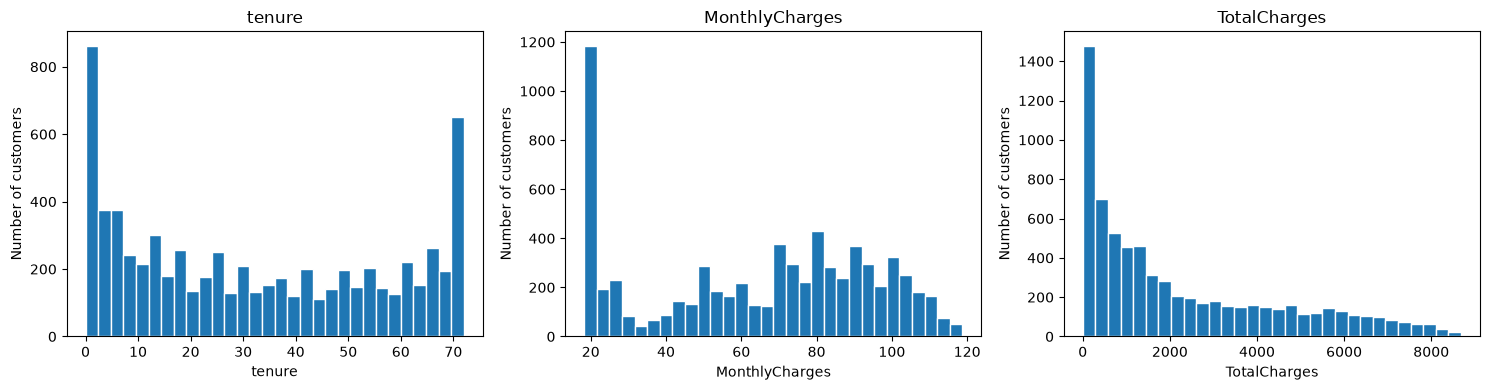

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    ax.hist(df[col], bins=30, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

In [14]:
df.groupby("Churn")[num_cols].median().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


- **Churners are much newer**, their median is 10 versus 38. Also **Churners pay more per month**, about $15 more at the median. Higher price, or the type of service behind it, seems linked to leaving.

In [15]:
df[num_cols].corr().round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


- Churners had lower total charges, but that was mostly because they had shorter tenure. Total charges is roughly tenure times monthly charges, so I treated it as a derived variable, not an independent driver.

In [16]:
#churn rate by customer characteristics
def churn_rate_table(data, col):
    summary = (
        data.assign(churned=data["Churn"].eq("Yes"))
            .groupby(col)
            .agg(customers=("churned", "size"), churn_rate=("churned", "mean"))
    )
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(1)
    return summary

overall_rate = df["Churn"].eq("Yes").mean() * 100

In [17]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    display(churn_rate_table(df, col).sort_values("churn_rate", ascending=False))

,customers,churn_rate
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


,customers,churn_rate
InternetService,,
Fiber optic,3096,41.9
DSL,2421,19.0
No,1526,7.4


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


,customers,churn_rate
TechSupport,,
No,3473,41.6
Yes,2044,15.2
No internet service,1526,7.4


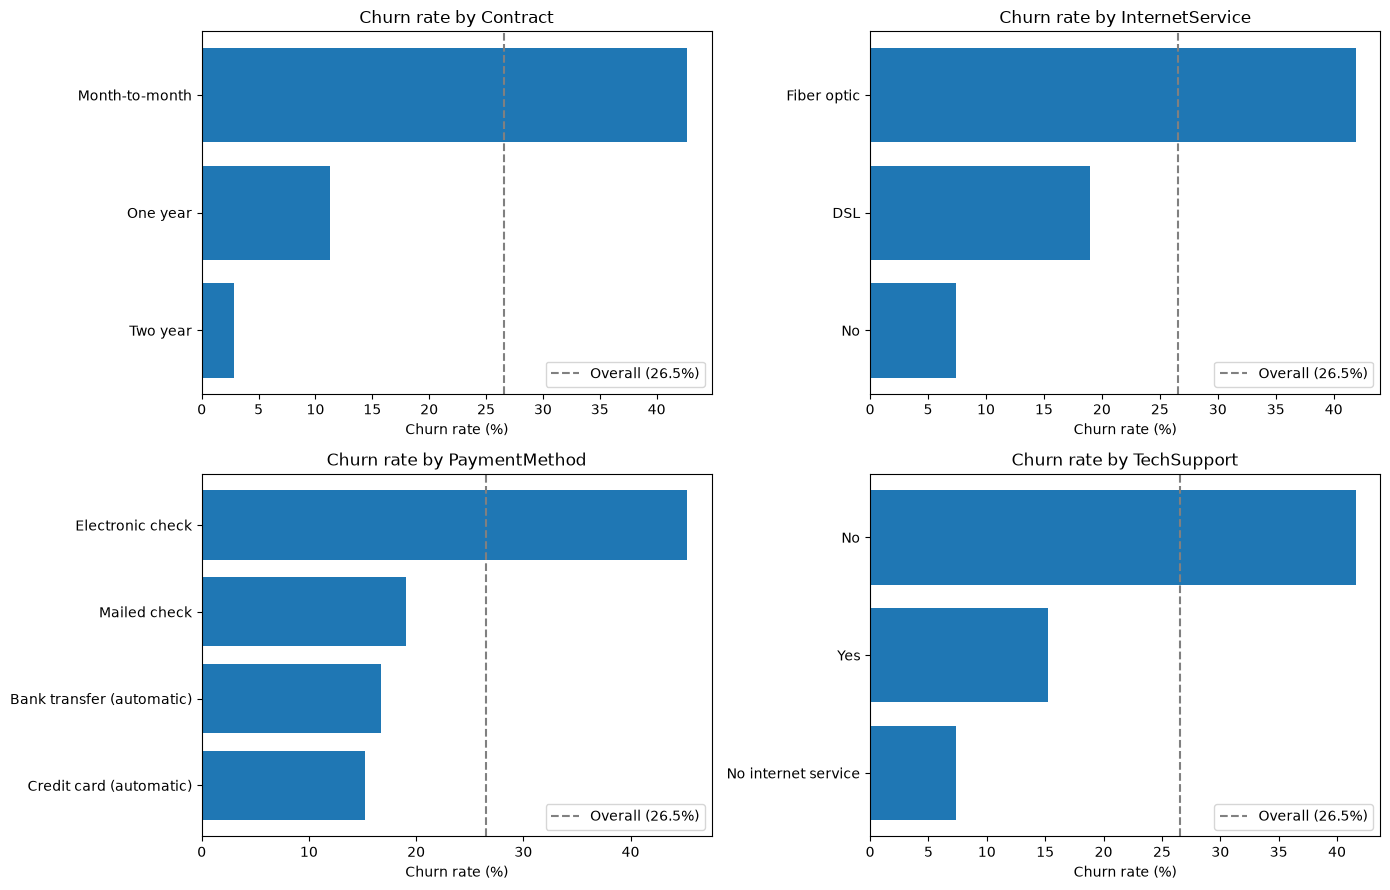

In [18]:
drivers = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flat, drivers):
    table = churn_rate_table(df, col).sort_values("churn_rate")
    ax.barh(table.index, table["churn_rate"])
    ax.axvline(overall_rate, color="gray", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../reports/figures/churn_rate_by_driver.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
df.groupby("InternetService")["MonthlyCharges"].median()

InternetService
DSL            56.150
Fiber optic    91.675
No             20.150
Name: MonthlyCharges, dtype: float64

- Month-to-month customers churn about 15 times as often as two-year customers. They’re also 55% of the customer base, so this isn’t a niche segment.

- Internet service: fiber optic churns at 41.9%, more than double DSL (19.0%). Combined with the earlier finding that fiber customers pay a median of about $92/month, the likely explanation is price relative to perceived value, or possibly service quality.

- Payment method: electronic check churns at 45.3%, while both automatic methods sit around 15–17%. One plausible reason: with manual payment, every bill is a moment where the customer actively decides to keep paying. Automatic payment removes that decision point.

- Tech support: customers without it churn at 41.6% versus 15.2% with it.

In [20]:
#churn rate by tenure
tenure_band = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                     labels=["0-12 months", "13-24", "25-48", "49-72"])
churn_rate_table(df.assign(tenure_band=tenure_band), "tenure_band")

,customers,churn_rate
tenure_band,,
0-12 months,2186,47.4
13-24,1024,28.7
25-48,1594,20.4
49-72,2239,9.5


- Almost half of first-year customers churn, about 5 times the rate of customers who’ve stayed 4+ years. This is a large group (2,186 customers, nearly a third of the base), so it’s a real pattern, not small-sample noise. The first 12 months are the critical retention window.

### An important caution
- Month-to-month, fiber, electronic check, no tech support, and short tenure are probably often the same customers. Each chart looks at one variable at a time, so we can’t yet tell which factors matter on their own and which just ride along with the others. For example, maybe electronic check users churn mostly because they tend to be on month-to-month contracts. That's why later in this analysis I will use SHAP to separate the effect of each feature on the outcome

## 4. Preprocessing

In [21]:
#split the dataset
from sklearn.model_selection import train_test_split

churn = df.copy()
 
X = churn.drop(columns=['customerID', 'Churn'])
y = churn['Churn'].map({'Yes': 1, 'No': 0})
customer_ids = churn['customerID'] #save for shap

print("Features:", X.shape)
print("Missing target values:", y.isna().sum())
print("Churn rate:", round(y.mean(), 3))

Features: (7043, 19)
Missing target values: 0
Churn rate: 0.265


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, stratify=y, random_state=SEED
)

In [23]:
#preprocess the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X_train.columns if col not in num_features]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    verbose_feature_names_out=False
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out().tolist()

X_train_prepared = pd.DataFrame(X_train_encoded, columns=feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(X_test_encoded, columns=feature_names, index=X_test.index)

print("Train:", X_train_prepared.shape)
print("Test: ", X_test_prepared.shape)


Train: (5634, 46)
Test:  (1409, 46)


In [24]:
#sanity check
print("Train numeric means:", X_train_encoded[:, :3].mean(axis=0).round(2))
print("Test numeric means: ", X_test_encoded[:, :3].mean(axis=0).round(2))

Train numeric means: [-0. -0. -0.]
Test numeric means:  [-0.02 -0.03 -0.04]


## 5. Baseline Model - Logistic Regression

In [25]:
#build and train the model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_reg_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=SEED))
])

log_reg_pipeline.fit(X_train, y_train)

y_pred_lr = log_reg_pipeline.predict(X_test)
y_prob_lr = log_reg_pipeline.predict_proba(X_test)[:, 1]

In [26]:
#evaluate the model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

results = [evaluate_model("Logistic Regression", y_test, y_pred_lr, y_prob_lr)]
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842


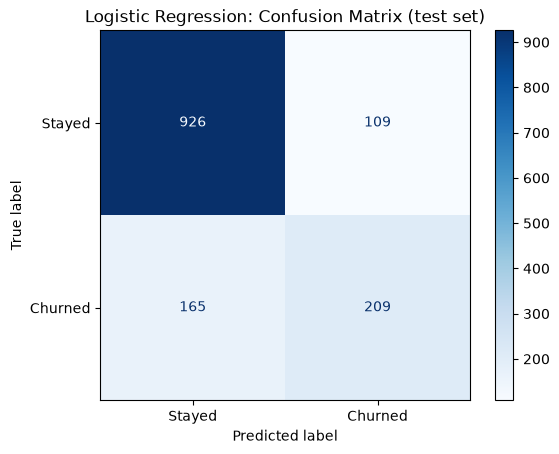

In [27]:
#confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=["Stayed", "Churned"], cmap="Blues"
)
plt.title("Logistic Regression: Confusion Matrix (test set)")
plt.show()

- Accuracy on the test set achieved a value of 0.8, only 7 point higher than predicting 'stay' for everyone (0.735).

- Recall around 0.56, the model only caught half of the customers who really churned

- Precision about 0.66, about 2 of every 3 flagged customers really were going to churn; 1 in 3 is a false alarm.

- This project will use recall with an acceptable precision as the main evaluation metric, as accuracy is not a suitable metric to evaluate model where dataset is imbalanced.

- To achieve a higher recall value, I will try lower the threshold, which I will try later, to catch more churners at the risk of false alarms, as missing churners are more costly.

## 6. Model Comparison

Beside the baseline model, I also try some more possible models for this problem to compare and find the most suitable model:

- **Random Forest**: builds hundreds of decision trees, each on a random sample of customers and features, then lets them vote. Trees can capture interactions that Logistic Regression can’t on its own, like “fiber optic and month-to-month and new customer.”

- **Gradient Boosting**: builds trees one after another, each correcting the errors of the previous ones. Often the strongest approach on tabular data.

- **XGBoost**: a fast, heavily optimized version of gradient boosting with built-in regularization (penalties that discourage overfitting). Widely used in industry.

In [28]:
#define the model
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=SEED),
    'XGBoost': XGBClassifier(random_state=SEED)
}

def make_pipeline(model):
    return Pipeline([("preprocess", clone(preprocessor)), ("model", model)])

In [29]:
#train the model
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1": "f1", "ROC-AUC": "roc_auc"}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["ROC-AUC std"] = scores["test_ROC-AUC"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_results.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC std
Model,,,,,,
Gradient Boosting,0.804,0.663,0.529,0.588,0.848,0.013
Logistic Regression,0.802,0.652,0.544,0.592,0.846,0.013
XGBoost,0.784,0.612,0.515,0.559,0.825,0.007
Random Forest,0.788,0.633,0.483,0.547,0.821,0.012


- **Gradient Boosting and Logistic Regression are effectively tied**: GB has a higher value of ROC-AUC value by 0.002, but the fold-to-fold variation is 0.013. A difference of only 0.002 is so small compared with the normal variation across folds that it is not strong evidence that Gradient Boosting is truly better.

- **XGBoost and Random Forest are falling behind**: at their default settings, all of the metrics are relatively lower than GB and LR, a possible reason is that their default settings are too aggressive for a dataset this size.

- **All models have recall values from 0.48 to 0.54 at the 0.5 threshold**: this confirms that lowering the threshold can improve the performance of the models

- In the next section, I will carry Gradient Boosting and Logistic Regression into, as GB has the most room with tuning, and LR be the bar for GB to beat.

## 7. Class Imbalance and Threshold Tuning

### Why SMOTE was not used
- **Imbalance is moderate:** 26.5% of customers churned, so the training set still has ~1,500 real churners to learn from.

- **Simpler tools address the same problem:** class weighting and threshold tuning shift the model toward catching more churners without creating artificial data.
- **SMOTE fits this data poorly:** it creates synthetic customers by interpolating between real ones. With one-hot encoded categories, that produces impossible values (e.g., "0.4 of a two-year contract") unless a special variant (SMOTENC) is used, which adds complexity and a new dependency.

- **If used, SMOTE must be applied only to training data, inside the pipeline.** Applying it before the train/test split lets synthetic points built from test customers leak into training, and puts near-copies of the same customer on both sides of the split. That inflates evaluation scores and makes the model look better than it will perform on real new customers.

In [30]:
#cross-validation helper
def cv_summary(name, pipeline, fit_params=None):
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring=scoring, params=fit_params)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    return row

In [31]:
from sklearn.utils.class_weight import compute_sample_weight

train_weights = compute_sample_weight("balanced", y_train)

imbalance_rows = [
    cv_summary("LR (default)",
               make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED))),
    cv_summary("LR (balanced)",
               make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                random_state=SEED))),
    cv_summary("GB (default)",
               make_pipeline(GradientBoostingClassifier(random_state=SEED))),
    cv_summary("GB (balanced)",
               make_pipeline(GradientBoostingClassifier(random_state=SEED)),
               fit_params={"model__sample_weight": train_weights}),
]

pd.DataFrame(imbalance_rows).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
LR (default),0.802,0.652,0.544,0.592,0.846
LR (balanced),0.748,0.517,0.801,0.628,0.846
GB (default),0.804,0.663,0.529,0.588,0.848
GB (balanced),0.751,0.521,0.787,0.627,0.848


- Class weighting raised recall from 0.54 to 0.80, but ROC-AUC was unchanged, so it was just shifting the decision boundary. I used threshold tuning on the unweighted model instead, which gave the same trade-off while keeping probabilities interpretable for risk segmentation.

In [32]:
#out-of-fold probabilities
from sklearn.model_selection import cross_val_predict

oof_prob_lr = cross_val_predict(
    make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_prob_gb = cross_val_predict(
    make_pipeline(GradientBoostingClassifier(random_state=SEED)),
    X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

What “out-of-fold” means: using the same 5 folds as before, each training customer gets a churn probability from a model that was not trained on them. The result is an honest probability for all 5,634 training customers, which we can safely use to test thresholds.

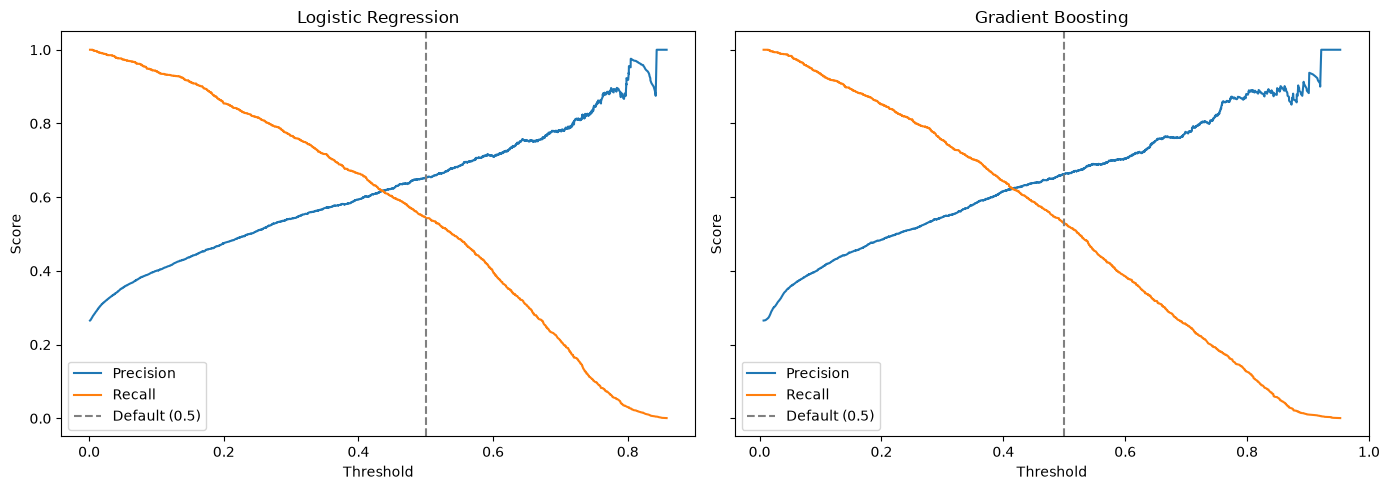

In [33]:
from sklearn.metrics import precision_recall_curve

def plot_threshold_tradeoff(ax, y_true, probs, title):
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    ax.plot(thresholds, precision[:-1], label="Precision")
    ax.plot(thresholds, recall[:-1], label="Recall")
    ax.axvline(0.5, color="gray", linestyle="--", label="Default (0.5)")
    ax.set_title(title)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_threshold_tradeoff(axes[0], y_train, oof_prob_lr, "Logistic Regression")
plot_threshold_tradeoff(axes[1], y_train, oof_prob_gb, "Gradient Boosting")
plt.tight_layout()
plt.show()

In [34]:
def threshold_table(y_true, probs, thresholds):
    rows = []
    for t in thresholds:
        pred = (probs >= t).astype(int)
        rows.append({
            "Threshold": t,
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "Flagged %": pred.mean() * 100,
        })
    return pd.DataFrame(rows).round(3)

candidate_thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
display(threshold_table(y_train, oof_prob_lr, candidate_thresholds))
display(threshold_table(y_train, oof_prob_gb, candidate_thresholds))

,Threshold,Precision,Recall,F1,Flagged %
0,0.20,0.475,0.854,0.610,47.728
1,0.25,0.509,0.817,0.627,42.599
2,0.30,0.541,0.767,0.634,37.593
3,0.35,0.571,0.717,0.635,33.351
4,0.40,0.594,0.664,0.627,29.659
5,0.45,0.624,0.601,0.612,25.577
6,0.50,0.652,0.544,0.593,22.133


,Threshold,Precision,Recall,F1,Flagged %
0,0.20,0.485,0.852,0.618,46.628
1,0.25,0.513,0.811,0.629,41.906
2,0.30,0.546,0.755,0.634,36.723
3,0.35,0.579,0.703,0.635,32.215
4,0.40,0.616,0.643,0.629,27.689
5,0.45,0.638,0.587,0.611,24.388
6,0.50,0.662,0.529,0.588,21.193


**Threshold choice**
- Within capacity, the possible choices for the threshold is between 0.3 to 0.35.

- At 0.5 the model caught only 54% of churners. I chose a **0.30** threshold, which raises recall to 77%, accepting lower precision because missed churners cost more than unnecessary offers.

## 8. Hyperparameter Tuning

**Two search Strategies**
- **GridSearchCV** tries every combination. That’s fine for small grids, like Logistic Regression’s one setting.

- **RandomizedSearchCV** tries a random sample of combinations. With 5 settings, a full grid explodes quickly; ours has 1,280 combinations. Sampling 30 usually finds a near-best configuration at a fraction of the cost.

In [35]:
#tune gradient boosting
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

gb_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [2, 3, 4, 5],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__min_samples_leaf": [1, 5, 10, 20],
}

gb_search = RandomizedSearchCV(
    make_pipeline(GradientBoostingClassifier(random_state=SEED)),
    gb_param_grid,
    n_iter=30,
    scoring="roc_auc",
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    return_train_score=True,
)
gb_search.fit(X_train, y_train)

print("Best ROC-AUC:", round(gb_search.best_score_, 3))
print("Best settings:", gb_search.best_params_)

Best ROC-AUC: 0.85
Best settings: {'model__subsample': 0.9, 'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_depth': 3, 'model__learning_rate': 0.03}


In [36]:
#top 5 configurations
gb_cv = pd.DataFrame(gb_search.cv_results_)
gb_cv["overfit_gap"] = gb_cv["mean_train_score"] - gb_cv["mean_test_score"]

(gb_cv[["params", "mean_test_score", "std_test_score", "mean_train_score", "overfit_gap"]]
    .sort_values("mean_test_score", ascending=False)
    .head(5)
    .round(3))

,params,mean_test_score,std_test_score,mean_train_score,overfit_gap
27,"{'model__subsample': 0.9, 'model__n_estimators...",0.850,0.011,0.876,0.025
3,"{'model__subsample': 0.9, 'model__n_estimators...",0.850,0.013,0.867,0.016
8,"{'model__subsample': 0.8, 'model__n_estimators...",0.850,0.011,0.897,0.048
13,"{'model__subsample': 0.7, 'model__n_estimators...",0.850,0.012,0.859,0.009
28,"{'model__subsample': 0.9, 'model__n_estimators...",0.849,0.011,0.895,0.046


In [37]:
#tune logistic regression
lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    {"model__C": [0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
)
lr_search.fit(X_train, y_train)

print("Best ROC-AUC:", round(lr_search.best_score_, 3))
print("Best C:", lr_search.best_params_)

Best ROC-AUC: 0.846
Best C: {'model__C': 100}


In [38]:
pd.DataFrame(lr_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(4)

,param_model__C,mean_test_score,std_test_score
0,0.01,0.8435,0.0111
1,0.10,0.8455,0.0120
2,1.00,0.8461,0.0126
3,10.00,0.8464,0.0128
4,100.00,0.8464,0.0129


**Final Model**

I will choose Logistic Regression as the final model. Tuning Gradient Boosting improved AUC only by 0.002, and it does not separated from Logistic Regression. I choose Logistic Regression as it provides similar performance, is simpler, and is a faster model.

## 9. Final Model and Test-Set Evaluation

In [39]:
FINAL_THRESHOLD = 0.3

final_pipeline = make_pipeline(LogisticRegression(max_iter=1000, C=1, random_state=SEED))
final_pipeline.fit(X_train, y_train);

In [40]:
y_prob_final = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob_final >= 0.5).astype(int)
y_pred_final = (y_prob_final >= FINAL_THRESHOLD).astype(int)

gb_best = gb_search.best_estimator_
y_prob_gb_test = gb_best.predict_proba(X_test)[:, 1]
y_pred_gb_test = (y_prob_gb_test >= FINAL_THRESHOLD).astype(int)

test_table = pd.DataFrame([
    evaluate_model("LR >= 0.50 (default)", y_test, y_pred_default, y_prob_final),
    evaluate_model("LR >= 0.30 (FINAL)", y_test, y_pred_final, y_prob_final),
    evaluate_model("Tuned GB >= 0.30 (reference only)", y_test, y_pred_gb_test, y_prob_gb_test),
]).set_index("Model")

test_table["Flagged %"] = [p.mean() * 100 for p in (y_pred_default, y_pred_final, y_pred_gb_test)]
test_table.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Flagged %
Model,,,,,,
LR >= 0.50 (default),0.806,0.657,0.559,0.604,0.842,22.569
LR >= 0.30 (FINAL),0.749,0.519,0.754,0.615,0.842,38.538
Tuned GB >= 0.30 (reference only),0.762,0.536,0.757,0.627,0.846,37.473


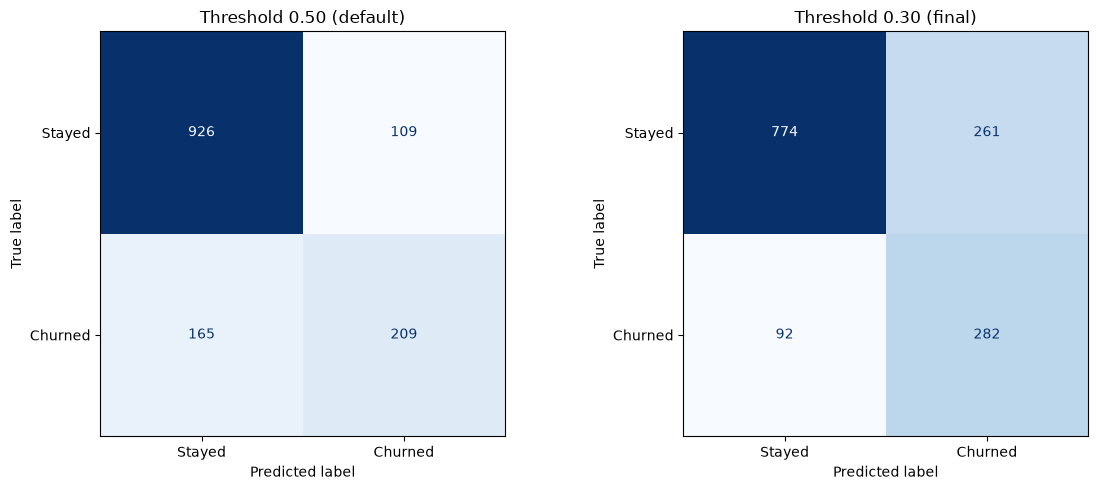

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip(axes, [y_pred_default, y_pred_final],
                            ["Threshold 0.50 (default)", "Threshold 0.30 (final)"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, display_labels=["Stayed", "Churned"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrices_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

- Tuned Gradient Boosting scored marginally higher on the test set, but I’d already committed to Logistic Regression based on cross-validation. Switching after seeing test results would bias the evaluation.

In [42]:
#save the final model
import joblib

Path("../models").mkdir(exist_ok=True)
joblib.dump(
    {"pipeline": final_pipeline, "threshold": FINAL_THRESHOLD},
    "../models/churn_model.joblib",
)

['../models/churn_model.joblib']

## 10. Explainable AI (SHAP)

In [43]:
import shap

preprocess_step = final_pipeline.named_steps['preprocess']
lr_model = final_pipeline.named_steps['model']
shap_feature_names = preprocess_step.get_feature_names_out()

X_train_transformed = pd.DataFrame(
    preprocess_step.transform(X_train),
    columns=shap_feature_names,
    index=X_train.index
)

X_test_transformed = pd.DataFrame(
    preprocess_step.transform(X_test),
    columns=shap_feature_names,
    index=X_test.index
)

background = shap.maskers.Independent(X_train_transformed, max_samples=len(X_train_transformed))
explainer = shap.LinearExplainer(lr_model, background)
shap_values = explainer(X_test_transformed)

In [44]:
#verify
i = 0
log_odds = shap_values.base_values[i] + shap_values.values[i].sum()
prob_from_shap = 1 / (1 + np.exp(-log_odds)) #convert to probability

print("Probability rebuilt from SHAP:", round(prob_from_shap, 4))
print("Probability from the model:   ", round(y_prob_final[i], 4))

Probability rebuilt from SHAP: 0.0461
Probability from the model:    0.0461


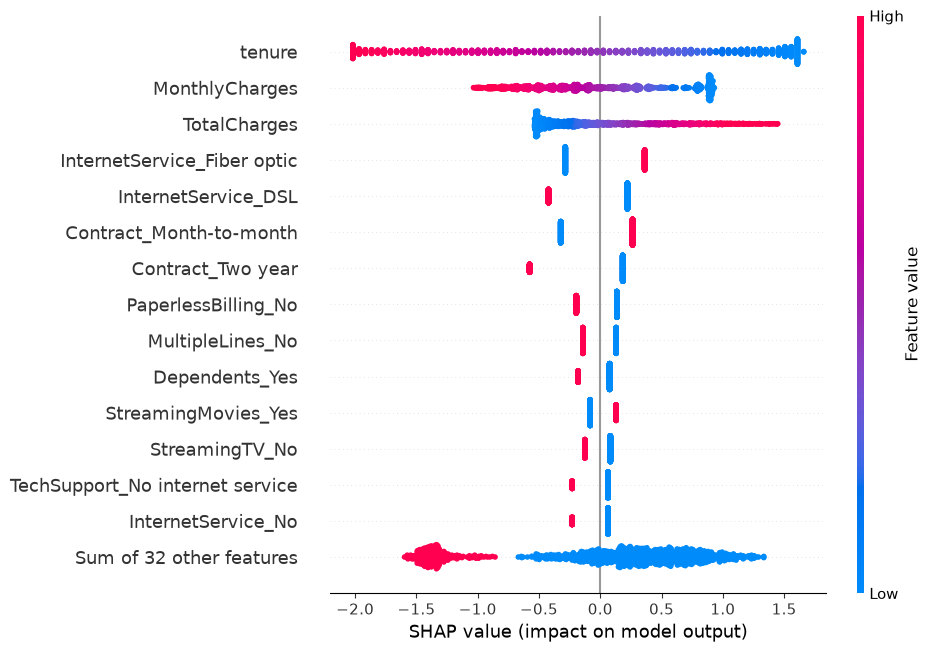

In [45]:
#beeswarm plot
shap.plots.beeswarm(shap_values, max_display=15)

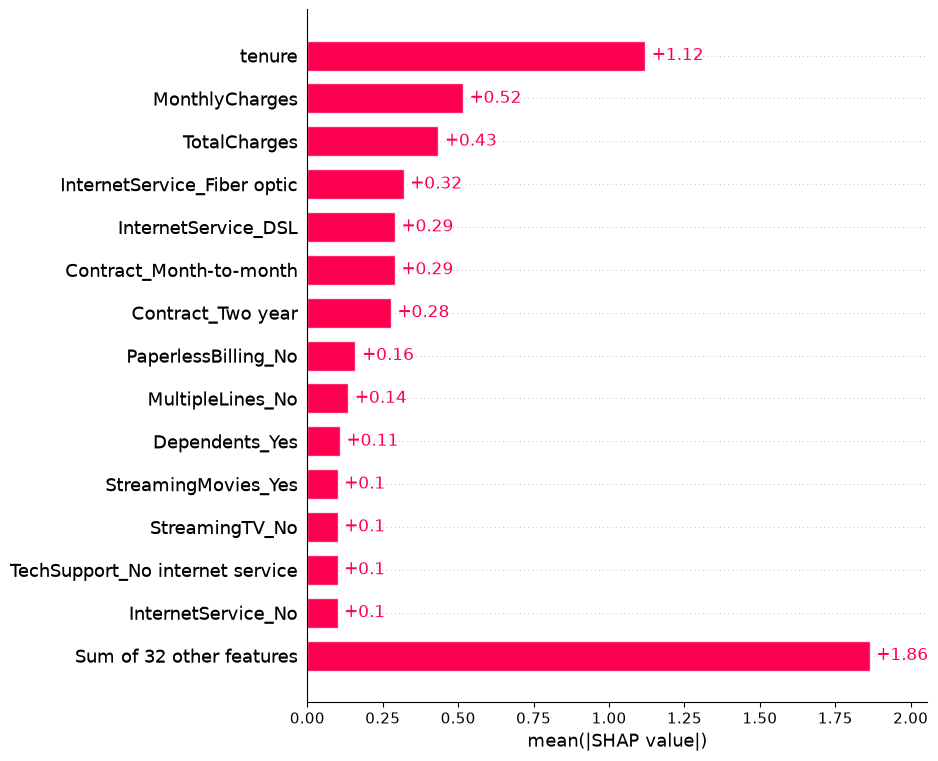

In [46]:
shap.plots.bar(shap_values, max_display=15)

### Note on correlated features
SHAP showed high MonthlyCharges *lowering* churn risk and high TotalCharges *raising* it, the opposite of the EDA findings. This is a multicollinearity artifact: TotalCharges ≈ tenure × MonthlyCharges, and MonthlyCharges largely reflects which services a customer has (already captured by the service features). The model assigns these overlapping features offsetting weights, so their individual signs are not meaningful.

**Decision:** the model is kept unchanged (it performs well and has already been evaluated on the test set). For interpretation, tenure, MonthlyCharges, and TotalCharges are combined into one "Tenure & billing" group, whose net effect is meaningful.

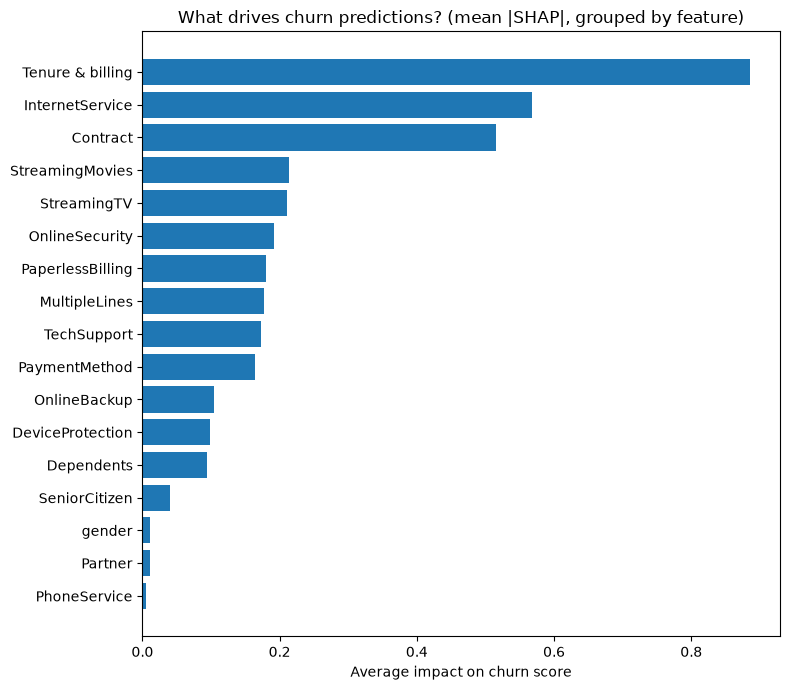

In [47]:
#group one-hot-encoding back to business features
def original_feature(column):
    for feature in X_train.columns:
        if column == feature or column.startswith(feature + "_"):
            return feature

billing_features = {"tenure", "MonthlyCharges", "TotalCharges"}

def business_group(column):
    feature = original_feature(column)
    return "Tenure & billing" if feature in billing_features else feature

shap_df = pd.DataFrame(shap_values.values, columns=shap_feature_names, index=X_test.index)
feature_map = {col: business_group(col) for col in shap_feature_names}
grouped_shap = shap_df.T.groupby(feature_map).sum().T

grouped_importance = grouped_shap.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(grouped_importance.index, grouped_importance.values)
ax.set_title("What drives churn predictions? (mean |SHAP|, grouped by feature)")
ax.set_xlabel("Average impact on churn score")
plt.tight_layout()
plt.savefig("../reports/figures/shap_grouped_importance.png", dpi=150, bbox_inches="tight")
plt.show()

- As we can see from the plot, Tenure & blling, InternetService, and Contract by far the top drivers churned prediction. These three are also the clearest business levers: early-life retention, contract upgrades, and the fiber customer experience.

- PaymentMethod ranked 10: in EDA, electronic check had a 45% churn rate, one of the most striking numbers. Once the model accounts for contract, tenure, and internet service at the same time, payment method adds relatively little on its own. TechSupport also follows the same pattern: a big EDA gap (41.6% vs 15.2%), but modest importance in the model.

In [48]:
results_test = pd.DataFrame({
    "customerID": customer_ids.loc[X_test.index],
    "churn_prob": y_prob_final,
    "actual": y_test,
    "predicted": y_pred_final,
}, index=X_test.index)

results_test.head()

,customerID,churn_prob,actual,predicted
437,4376-KFVRS,0.046059,0,0
2280,2754-SDJRD,0.683648,0,1
2235,9917-KWRBE,0.058725,0,0
4460,0365-GXEZS,0.401120,0,1
3761,9385-NXKDA,0.021637,0,0


In [49]:
#find specific customers for shap
#a high-risk churned customer the model caught    
churned_idx = results_test.query(
    "actual == 1 and predicted == 1"
)["churn_prob"].idxmax()

#a low-risk customer who stayed
stayed_idx = results_test.query(
    "actual == 0 and predicted == 0"
)["churn_prob"].idxmin()

#a churned customer that the model missed
missed_idx = results_test.query(
    "actual == 1 and predicted == 0"
)["churn_prob"].idxmin()

instances_to_explain = X_test.loc[
    [churned_idx, stayed_idx, missed_idx]
]

instances_to_explain

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10
2338,Male,0,Yes,Yes,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.95,1322.85
4386,Male,0,Yes,Yes,55,Yes,No,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Bank transfer (automatic),57.55,3046.40


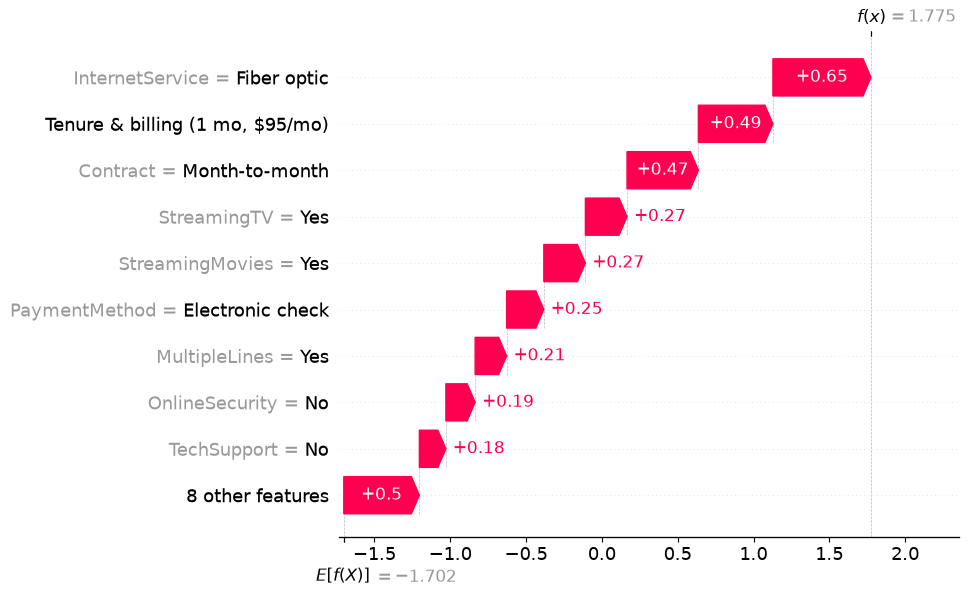

In [50]:
#churned customer SHAP plot
row_churned = X_test.loc[churned_idx]

churned_labels = []
for group in grouped_shap.columns:
    if group == "Tenure & billing":
        churned_labels.append(f"Tenure & billing ({row_churned['tenure']} mo, ${row_churned['MonthlyCharges']:.0f}/mo)")
    else:
        churned_labels.append(f"{group} = {row_churned[group]}")

churned_customer_shap = shap.Explanation(
    values=grouped_shap.loc[churned_idx].to_numpy(),
    base_values=explainer.expected_value,
    feature_names=churned_labels,
)

shap.plots.waterfall(churned_customer_shap, max_display=10, show=False)
plt.savefig("../reports/figures/customer_waterfall_high_risk.png", dpi=150, bbox_inches="tight")
plt.show()

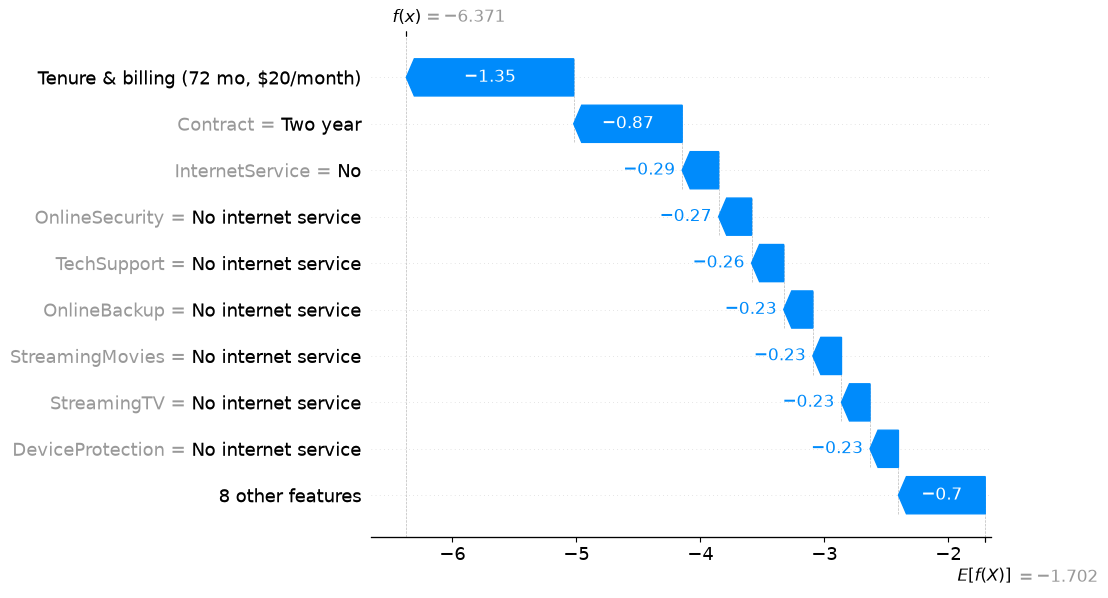

In [51]:
#stayed custormer SHAP plot
row_stayed = X_test.loc[stayed_idx]

stayed_labels = []
for group in grouped_shap.columns:
    if group == "Tenure & billing":
        stayed_labels.append(f"Tenure & billing ({row_stayed['tenure']} mo, ${row_stayed['MonthlyCharges']:.0f}/month)")
    else:
        stayed_labels.append(f'{group} = {row_stayed[group]}')

stayed_customer_shap = shap.Explanation(
    values=grouped_shap.loc[stayed_idx].to_numpy(),
    base_values=explainer.expected_value,
    feature_names=stayed_labels,
)

shap.plots.waterfall(stayed_customer_shap, max_display=10)
plt.show()

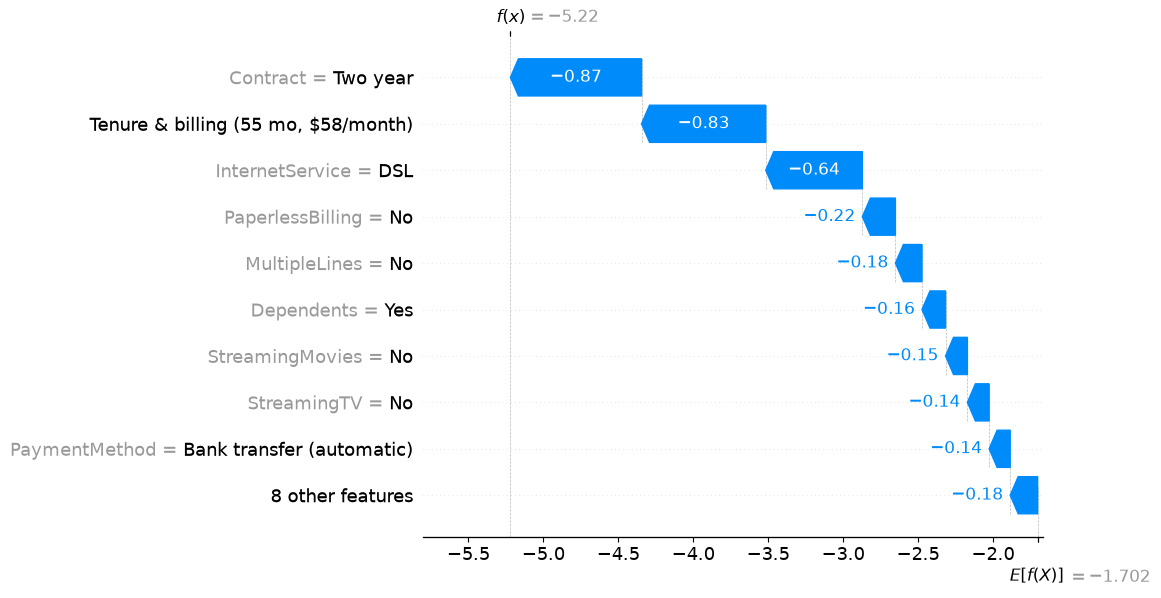

In [52]:
#missed customer SHAP plot
row_missed = X_test.loc[missed_idx]

missed_labels = []
for group in grouped_shap.columns:
    if group == 'Tenure & billing':
        missed_labels.append(f'Tenure & billing ({row_missed['tenure']} mo, ${row_missed['MonthlyCharges']:.0f}/month)')
    else:
        missed_labels.append(f'{group} = {row_missed[group]}')

missed_customer_shap = shap.Explanation(
    values=grouped_shap.loc[missed_idx].to_numpy(),
    base_values=explainer.expected_value,
    feature_names=missed_labels
)

shap.plots.waterfall(missed_customer_shap, max_display=10, show=False)
plt.savefig("../reports/figures/customer_waterfall_missed.png", dpi=150, bbox_inches='tight')
plt.show()

- We can see from the plot, every feature the model can see point to the customer being the loyal customer who was gonna stay: 2-year contract, 4.5 year of tenure, InternetService = DSL and so on.

- The model is not careless here, it's probaly because the reason this customer churned did not come from the data itself, but because of external factors, such as moving, a competitor offer, or a service problem.

## 11. Customer Risk Segmentation

Goal: turn each customer’s churn probability into a risk tier the retention team can act on, then size each tier by customers and revenue, and describe who sits in it.

- Below 0.3: Low risk (Not contacted)
- From 0.3 to 0.5: Medium risk (Low-cost touch)
- From 0.5 to 0.7: High risk (Proactive outreach)
- Above 0.7: Critical risk (Priority)

**The cutoffs above 0.30 are a business judgment, not a statistical result.**

In [53]:
risk_bins = [0, 0.30, 0.50, 0.70, np.inf]
risk_labels = ["Low", "Medium", "High", "Critical"]

segments = X_test.copy()
segments["customerID"] = customer_ids.loc[X_test.index]
segments["churn_prob"] = y_prob_final
segments["actual_churn"] = y_test
segments["risk_level"] = pd.cut(segments["churn_prob"], bins=risk_bins,
                                labels=risk_labels, right=False)
segments["expected_monthly_loss"] = segments["churn_prob"] * segments["MonthlyCharges"]
segments["key_churn_driver"] = grouped_shap.idxmax(axis=1)
segments["key_churn_drivers"] = grouped_shap.apply(
    lambda row: ", ".join(row[row > 0].nlargest(2).index), axis=1
)

segments["risk_level"].value_counts().sort_index()

risk_level
Low         866
Medium      225
High        225
Critical     93
Name: count, dtype: int64

In [54]:
tier_summary = segments.groupby("risk_level", observed=True).agg(
    customers=("customerID", "size"),
    avg_predicted_prob=("churn_prob", "mean"),
    actual_churn_rate=("actual_churn", "mean"),
    monthly_revenue=("MonthlyCharges", "sum"),
    expected_monthly_loss=("expected_monthly_loss", "sum"),
)
tier_summary["customer_share_%"] = tier_summary["customers"] / len(segments) * 100
tier_summary["revenue_share_%"] = tier_summary["monthly_revenue"] / tier_summary["monthly_revenue"].sum() * 100
tier_summary.round(2)

,customers,avg_predicted_prob,actual_churn_rate,monthly_revenue,expected_monthly_loss,customer_share_%,revenue_share_%
risk_level,,,,,,,
Low,866,0.09,0.11,48565.85,4979.22,61.46,53.78
Medium,225,0.40,0.32,16523.70,6698.65,15.97,18.30
High,225,0.60,0.62,17387.35,10461.20,15.97,19.25
Critical,93,0.75,0.74,7824.30,5887.50,6.60,8.66


- **Risk is concentrated**: The flagged 38.5% of customers carry 82% of the expected revenue loss. High + Critical alone (23% of customers) carry 58%. That’s the headline for the retention team: a focused list covers most of the risk.

In [55]:
#tier profile
profile = segments.groupby("risk_level", observed=True).agg(
    median_tenure=("tenure", "median"),
    median_monthly=("MonthlyCharges", "median"),
    month_to_month_pct=("Contract", lambda s: s.eq("Month-to-month").mean() * 100),
    fiber_pct=("InternetService", lambda s: s.eq("Fiber optic").mean() * 100),
    electronic_check_pct=("PaymentMethod", lambda s: s.eq("Electronic check").mean() * 100),
    no_tech_support_pct=("TechSupport", lambda s: s.eq("No").mean() * 100),
)
profile.round(1)

,median_tenure,median_monthly,month_to_month_pct,fiber_pct,electronic_check_pct,no_tech_support_pct
risk_level,,,,,,
Low,47.5,55.0,29.0,23.2,16.6,28.1
Medium,19.0,75.8,90.7,58.7,45.3,74.2
High,9.0,79.2,100.0,84.4,64.4,89.3
Critical,3.0,84.6,100.0,96.8,89.2,97.8


In [56]:
#most common churn drivers in the flagged tier
flagged = segments[segments["risk_level"] != "Low"]
pd.crosstab(flagged["key_churn_driver"], flagged["risk_level"].cat.remove_unused_categories())

risk_level,Medium,High,Critical
key_churn_driver,,,
Contract,6,0,0
InternetService,129,125,51
Tenure & billing,90,100,42


- Although 100% of high-risk customers appear to be month-to-month contracts, yet it is almost never the top driver. This is not contradtict with which I found, it is because the idxmax keeps only the largest factor. This means a feature can be highly associated with churn in the profile table without necessarily being the strongest SHAP contribution for most individual customers.

## 12. Business Impacts

- **Goal**: estimate whether a retention campaign aim at flagged customers would make money.

- **Note**: every number that I don't get from the data is an assumption.

### How the estimate works
A retention offer only protects revenue if it reaches someone who would have left. Offering a discount to a loyal customer protects nothing. So:

- **Revenue protected** = (expected monthly revenue at risk) × (success rate) × (months retained)
- **Campaign cost** = cost per contact × every flagged customer, including false alarms.

In [57]:
# Assumptions (illustrative, not from the data)
SUCCESS_RATE = 0.15      # share of would-be churners the campaign keeps
RETENTION_MONTHS = 12    # how long a saved customer stays
COST_PER_CONTACT = 25    # average cost per flagged customer: staff time + offer ($)

targeted = segments[segments["churn_prob"] >= FINAL_THRESHOLD]

monthly_revenue_at_risk = targeted["expected_monthly_loss"].sum()
revenue_protected = monthly_revenue_at_risk * SUCCESS_RATE * RETENTION_MONTHS
campaign_cost = len(targeted) * COST_PER_CONTACT
net_value = revenue_protected - campaign_cost
break_even_rate = campaign_cost / (monthly_revenue_at_risk * RETENTION_MONTHS)

print(f"Customers contacted:          {len(targeted)}")
print(f"Expected churners among them: {targeted['churn_prob'].sum():.0f}")
print(f"Monthly revenue at risk:      ${monthly_revenue_at_risk:,.0f}")
print(f"Revenue protected (12 mo):    ${revenue_protected:,.0f}")
print(f"Campaign cost:                ${campaign_cost:,.0f}")
print(f"Net value:                    ${net_value:,.0f}")
print(f"Break-even success rate:      {break_even_rate:.1%}")

Customers contacted:          543
Expected churners among them: 296
Monthly revenue at risk:      $23,047
Revenue protected (12 mo):    $41,485
Campaign cost:                $13,575
Net value:                    $27,910
Break-even success rate:      4.9%


In [58]:
sensitivity = pd.DataFrame({"success_rate": [0.05, 0.10, 0.15, 0.20, 0.25]})
sensitivity["revenue_protected"] = monthly_revenue_at_risk * sensitivity["success_rate"] * RETENTION_MONTHS
sensitivity["campaign_cost"] = campaign_cost
sensitivity["net_value"] = sensitivity["revenue_protected"] - campaign_cost
sensitivity["roi"] = sensitivity["net_value"] / campaign_cost
sensitivity.round(2)

,success_rate,revenue_protected,campaign_cost,net_value,roi
0,0.05,13828.41,13575,253.41,0.02
1,0.10,27656.82,13575,14081.82,1.04
2,0.15,41485.23,13575,27910.23,2.06
3,0.20,55313.64,13575,41738.64,3.07
4,0.25,69142.05,13575,55567.05,4.09


In [59]:
for threshold in [0.30, 0.50]:
    group = segments[segments["churn_prob"] >= threshold]
    protected = group["expected_monthly_loss"].sum() * SUCCESS_RATE * RETENTION_MONTHS
    cost = len(group) * COST_PER_CONTACT
    print(f"Threshold {threshold:.2f}: contact {len(group)}, "
          f"protected ${protected:,.0f}, cost ${cost:,.0f}, net ${protected - cost:,.0f}")

Threshold 0.30: contact 543, protected $41,485, cost $13,575, net $27,910
Threshold 0.50: contact 318, protected $29,428, cost $7,950, net $21,478


- Contacting the 543 flagged customers breaks even if the campaign keeps just 4.9% of would-be churners. At an assumed 15%, it returns about $2 per dollar spent, and the 0.30 threshold produced about $6,400 more net value than the default 0.5.

## 13. Final Prediction Table

In [60]:
final_table = (
    segments[["customerID", "churn_prob", "risk_level", "key_churn_drivers",
              "MonthlyCharges", "Contract", "tenure"]]
    .rename(columns={
        "customerID": "Customer ID",
        "churn_prob": "Churn Probability",
        "risk_level": "Risk Level",
        "key_churn_drivers": "Key Churn Drivers",
        "MonthlyCharges": "Monthly Charge",
        "Contract": "Contract",
        "tenure": "Tenure (months)",
    })
    .sort_values("Churn Probability", ascending=False)
)
final_table["Churn Probability"] = final_table["Churn Probability"].round(2)
final_table["Key Churn Drivers"] = final_table["Key Churn Drivers"].replace("", "No major risk factor")

Path("../reports").mkdir(exist_ok=True)
final_table.to_csv("../reports/customer_risk_predictions.csv", index=False)

final_table.head(5)

,Customer ID,Churn Probability,Risk Level,Key Churn Drivers,Monthly Charge,Contract,Tenure (months)
3380,5178-LMXOP,0.86,Critical,"InternetService, Tenure & billing",95.10,Month-to-month,1
6866,0295-PPHDO,0.83,Critical,"InternetService, Tenure & billing",95.45,Month-to-month,1
2631,6861-XWTWQ,0.83,Critical,"InternetService, Contract",99.25,Month-to-month,7
6365,8884-ADFVN,0.82,Critical,"InternetService, Contract",101.95,Month-to-month,7
4585,1069-XAIEM,0.82,Critical,"Tenure & billing, InternetService",85.05,Month-to-month,1
